In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [9]:
!pip install -q pandas numpy matplotlib scikit-learn tqdm pytorch-lightning

In [10]:
import os
import random
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from collections import defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import pytorch_lightning as pl

In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [12]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-20m.zip
!unzip -q ml-20m.zip

In [13]:
!ls ml-20m

genome-scores.csv  links.csv   ratings.csv  tags.csv
genome-tags.csv    movies.csv  README.txt


In [14]:
ratings = pd.read_csv("ml-20m/ratings.csv")
movies = pd.read_csv("ml-20m/movies.csv")

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

ratings.head()

Ratings shape: (20000263, 4)
Movies shape: (27278, 3)


,userId,movieId,rating,timestamp
0,1,2,3.5,1112486027
1,1,29,3.5,1112484676
2,1,32,3.5,1112484819
3,1,47,3.5,1112484727
4,1,50,3.5,1112484580


In [15]:
print(ratings.info())
print()
print(movies.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000263 entries, 0 to 20000262
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 610.4 MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  27278 non-null  int64 
 1   title    27278 non-null  object
 2   genres   27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB
None


In [16]:
print("Unique users:", ratings["userId"].nunique())
print("Unique movies:", ratings["movieId"].nunique())
print("Total interactions:", len(ratings))

Unique users: 138493
Unique movies: 26744
Total interactions: 20000263


In [17]:
all_raw_users = ratings["userId"].unique()

num_selected_users = int(len(all_raw_users) * 0.30)

selected_users = np.random.choice(
    all_raw_users,
    size=num_selected_users,
    replace=False
)

ratings = ratings[
    ratings["userId"].isin(selected_users)
].copy()

print("Selected users:", ratings["userId"].nunique())
print("Interactions:", len(ratings))
print("Movies:", ratings["movieId"].nunique())

Selected users: 41547
Interactions: 6048287
Movies: 22836


In [18]:
ratings = ratings.sort_values(
    ["userId", "timestamp"]
).reset_index(drop=True)

In [19]:
ratings["rank_latest"] = (
    ratings
    .groupby("userId")["timestamp"]
    .rank(method="first", ascending=False)
)

In [20]:
ratings.head(20)

,userId,movieId,rating,timestamp,rank_latest
0,1,924,3.5,1094785598,175.0
1,1,919,3.5,1094785621,174.0
2,1,2683,3.5,1094785650,173.0
3,1,1584,3.5,1094785656,172.0
4,1,1079,4.0,1094785665,171.0
5,1,653,3.0,1094785691,170.0
6,1,2959,4.0,1094785698,169.0
7,1,337,3.5,1094785709,168.0
8,1,1304,3.0,1094785720,167.0
9,1,3996,4.0,1094785727,166.0


In [21]:
test_ratings = ratings[
    ratings["rank_latest"] == 1
].copy()

train_ratings = ratings[
    ratings["rank_latest"] != 1
].copy()

In [22]:
train_ratings = train_ratings[
    ["userId", "movieId", "rating", "timestamp"]
].copy()

test_ratings = test_ratings[
    ["userId", "movieId", "rating", "timestamp"]
].copy()

In [23]:
print("Train interactions:", len(train_ratings))
print("Test interactions:", len(test_ratings))

Train interactions: 6006740
Test interactions: 41547


In [24]:
train_ratings["label"] = 1.0
test_ratings["label"] = 1.0

In [25]:
train_ratings = train_ratings[
    ["userId", "movieId", "label"]
].copy()

test_ratings = test_ratings[
    ["userId", "movieId", "label"]
].copy()

In [26]:
user_ids = sorted(ratings["userId"].unique())
movie_ids = sorted(ratings["movieId"].unique())

user2idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

movie2idx = {
    movie_id: idx
    for idx, movie_id in enumerate(movie_ids)
}

idx2user = {
    idx: user_id
    for user_id, idx in user2idx.items()
}

idx2movie = {
    idx: movie_id
    for movie_id, idx in movie2idx.items()
}

num_users = len(user2idx)
num_items = len(movie2idx)

print("Number of users:", num_users)
print("Number of movies:", num_items)

Number of users: 41547
Number of movies: 22836


In [27]:
train_ratings["user_idx"] = train_ratings["userId"].map(user2idx)
train_ratings["item_idx"] = train_ratings["movieId"].map(movie2idx)

test_ratings["user_idx"] = test_ratings["userId"].map(user2idx)
test_ratings["item_idx"] = test_ratings["movieId"].map(movie2idx)

In [28]:
print(train_ratings.isnull().sum())
print(test_ratings.isnull().sum())

userId      0
movieId     0
label       0
user_idx    0
item_idx    0
dtype: int64
userId      0
movieId     0
label       0
user_idx    0
item_idx    0
dtype: int64


In [29]:
user_interacted = defaultdict(set)

for row in train_ratings[["user_idx", "item_idx"]].itertuples(index=False):
    user_idx, item_idx = row
    user_interacted[user_idx].add(item_idx)

In [30]:
all_item_indices = np.arange(num_items)

In [31]:
NUM_NEGATIVES = 4

In [32]:
class MovieLensTrainDataset(Dataset):

    def __init__(
        self,
        train_ratings,
        user_interacted,
        num_items,
        num_negatives=4
    ):
        self.train_ratings = train_ratings
        self.user_interacted = user_interacted
        self.num_items = num_items
        self.num_negatives = num_negatives

        self.users = None
        self.items = None
        self.labels = None

        self.regenerate_negatives()

    def regenerate_negatives(self):

        users = []
        items = []
        labels = []

        for row in self.train_ratings[
            ["user_idx", "item_idx"]
        ].itertuples(index=False):

            user = int(row.user_idx)
            positive_item = int(row.item_idx)

            users.append(user)
            items.append(positive_item)
            labels.append(1.0)

            interacted = self.user_interacted[user]

            negative_count = 0

            while negative_count < self.num_negatives:

                negative_item = np.random.randint(
                    0,
                    self.num_items
                )

                if negative_item not in interacted:

                    users.append(user)
                    items.append(negative_item)
                    labels.append(0.0)

                    negative_count += 1

        self.users = torch.tensor(
            users,
            dtype=torch.long
        )

        self.items = torch.tensor(
            items,
            dtype=torch.long
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return (
            self.users[idx],
            self.items[idx],
            self.labels[idx]
        )

In [33]:
train_dataset = MovieLensTrainDataset(
    train_ratings=train_ratings,
    user_interacted=user_interacted,
    num_items=num_items,
    num_negatives=NUM_NEGATIVES
)

print("Training samples:", len(train_dataset))

Training samples: 30033700


In [34]:
for i in range(10):
    user, item, label = train_dataset[i]

    print(
        "User:",
        user.item(),
        "Item:",
        item.item(),
        "Label:",
        label.item()
    )

User: 0 Item: 907 Label: 1.0
User: 0 Item: 1583 Label: 0.0
User: 0 Item: 11881 Label: 0.0
User: 0 Item: 12927 Label: 0.0
User: 0 Item: 13059 Label: 0.0
User: 0 Item: 902 Label: 1.0
User: 0 Item: 20941 Label: 0.0
User: 0 Item: 12856 Label: 0.0
User: 0 Item: 19490 Label: 0.0
User: 0 Item: 19020 Label: 0.0


In [35]:
BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

In [36]:
users, items, labels = next(iter(train_loader))

print("Users shape:", users.shape)
print("Items shape:", items.shape)
print("Labels shape:", labels.shape)

Users shape: torch.Size([512])
Items shape: torch.Size([512])
Labels shape: torch.Size([512])


In [37]:
class NCF(nn.Module):

    def __init__(
        self,
        num_users,
        num_items,
        embedding_dim=8
    ):
        super().__init__()

        self.user_embedding = nn.Embedding(
            num_users,
            embedding_dim
        )

        self.item_embedding = nn.Embedding(
            num_items,
            embedding_dim
        )

        self.fc1 = nn.Linear(
            embedding_dim * 2,
            64
        )

        self.fc2 = nn.Linear(
            64,
            32
        )

        self.output = nn.Linear(
            32,
            1
        )

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(
        self,
        user_input,
        item_input
    ):

        user_embedded = self.user_embedding(
            user_input
        )

        item_embedded = self.item_embedding(
            item_input
        )

        vector = torch.cat(
            [
                user_embedded,
                item_embedded
            ],
            dim=-1
        )

        vector = self.relu(
            self.fc1(vector)
        )

        vector = self.relu(
            self.fc2(vector)
        )

        output = self.output(vector)

        prediction = self.sigmoid(output)

        return prediction.squeeze(-1)

In [38]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = NCF(
    num_users=num_users,
    num_items=num_items,
    embedding_dim=8
).to(device)

print(model)

NCF(
  (user_embedding): Embedding(41547, 8)
  (item_embedding): Embedding(22836, 8)
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)


In [39]:
users, items, labels = next(iter(train_loader))

users = users.to(device)
items = items.to(device)

predictions = model(users, items)

print("Prediction shape:", predictions.shape)
print(predictions[:10])

Prediction shape: torch.Size([512])
tensor([0.4734, 0.5110, 0.4915, 0.4555, 0.5153, 0.4886, 0.5036, 0.5056, 0.5236,
        0.5043], device='cuda:0', grad_fn=<SliceBackward0>)


In [40]:
criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [41]:
NUM_EPOCHS = 5

history = []

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    train_dataset.regenerate_negatives()

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    model.train()

    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}"
    )

    for users, items, labels in progress_bar:

        users = users.to(
            device,
            non_blocking=True
        )

        items = items.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        predictions = model(
            users,
            items
        )

        loss = criterion(
            predictions,
            labels
        )

        loss.backward()

        optimizer.step()

        current_batch_size = labels.size(0)

        running_loss += (
            loss.item() * current_batch_size
        )

        total_samples += current_batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = (
        running_loss / total_samples
    )

    history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1} Loss: "
        f"{epoch_loss:.4f}"
    )


Epoch 1/5


Epoch 1:   0%|          | 0/58660 [00:03<?, ?it/s]

Epoch 1 Loss: 0.2252

Epoch 2/5


Epoch 2:   0%|          | 0/58660 [00:03<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760><function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
        if w.is_alive():if w.is_alive():

              ^^^^^^^^^^^^^^^^^^^^^^^^

  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
        assert self.

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760>Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760>
Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
Traceback (most recent call last):
    self._shutdown_workers()  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    
self._shutdown_workers()  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers

      File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
if w.is_alive():    
if w.is_alive():   
      ^ ^ ^ ^^  ^^^^^^^^^^^^^^^^^^
^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
        assert self.

Epoch 4 Loss: 0.1814

Epoch 5/5


Epoch 5:   0%|          | 0/58660 [00:03<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760><function _MultiProcessingDataLoaderIter.__del__ at 0x781137dad760>
Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
        self._shutdown_workers()self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
        if w.is_alive():if w.is_alive():

              ^^^^^^^^^^^^^^^^^^^^^^^^

  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
        assert self.

Epoch 5 Loss: 0.1781


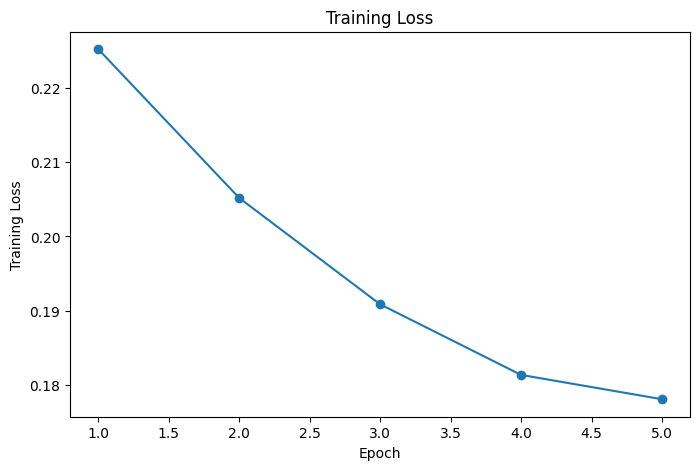

In [42]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")

plt.show()

In [43]:
user_idx = 0

candidate_items = np.array(
    list(range(num_items))
)

In [44]:
interacted_items = user_interacted[user_idx]

candidate_items = np.array([
    item
    for item in candidate_items
    if item not in interacted_items
])

print(
    "Candidate movies:",
    len(candidate_items)
)

Candidate movies: 22662


In [45]:
model.eval()

user_tensor = torch.tensor(
    [user_idx] * len(candidate_items),
    dtype=torch.long
).to(device)

item_tensor = torch.tensor(
    candidate_items,
    dtype=torch.long
).to(device)

with torch.no_grad():

    scores = model(
        user_tensor,
        item_tensor
    )

In [46]:
scores = scores.cpu()

top_k = 10

top_indices = torch.argsort(
    scores,
    descending=True
)[:top_k]

recommended_internal_ids = candidate_items[
    top_indices.numpy()
]

recommended_scores = scores[
    top_indices
].numpy()

In [47]:
for item_idx, score in zip(
    recommended_internal_ids,
    recommended_scores
):

    raw_movie_id = idx2movie[int(item_idx)]

    print(
        "Movie ID:",
        raw_movie_id,
        "Score:",
        float(score)
    )

Movie ID: 2571 Score: 0.9823254942893982
Movie ID: 2858 Score: 0.9790254235267639
Movie ID: 356 Score: 0.9769575595855713
Movie ID: 1270 Score: 0.9717243909835815
Movie ID: 1580 Score: 0.970838189125061
Movie ID: 480 Score: 0.9698755741119385
Movie ID: 1 Score: 0.9674372673034668
Movie ID: 527 Score: 0.9658104181289673
Movie ID: 1210 Score: 0.9655659198760986
Movie ID: 858 Score: 0.9630992412567139


In [48]:
recommended_movie_ids = [
    idx2movie[int(idx)]
    for idx in recommended_internal_ids
]

recommendations = movies[
    movies["movieId"].isin(
        recommended_movie_ids
    )
].copy()

recommendations = recommendations[
    ["movieId", "title", "genres"]
]

recommendations

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
352,356,Forrest Gump (1994),Comedy|Drama|Romance|War
476,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
523,527,Schindler's List (1993),Drama|War
843,858,"Godfather, The (1972)",Crime|Drama
1184,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi
1242,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi
1528,1580,Men in Black (a.k.a. MIB) (1997),Action|Comedy|Sci-Fi
2486,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller
2772,2858,American Beauty (1999),Comedy|Drama


In [49]:
def recommend_movies(
    model,
    user_id,
    top_k=10
):
    model.eval()

    user_idx = user2idx[user_id]

    interacted_items = user_interacted[
        user_idx
    ]

    candidate_items = [
        item
        for item in range(num_items)
        if item not in interacted_items
    ]

    user_tensor = torch.tensor(
        [user_idx] * len(candidate_items),
        dtype=torch.long,
        device=device
    )

    item_tensor = torch.tensor(
        candidate_items,
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():

        scores = model(
            user_tensor,
            item_tensor
        )

    scores = scores.cpu()

    top_indices = torch.argsort(
        scores,
        descending=True
    )[:top_k]

    top_items = np.array(
        candidate_items
    )[top_indices.numpy()]

    top_scores = scores[
        top_indices
    ].numpy()

    result = []

    for item_idx, score in zip(
        top_items,
        top_scores
    ):

        raw_movie_id = idx2movie[
            int(item_idx)
        ]

        movie_row = movies[
            movies["movieId"] == raw_movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        result.append({
            "movieId": int(raw_movie_id),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "score": float(score)
        })

    return result

In [50]:
test_user_id = user_ids[0]

recommendations = recommend_movies(
    model,
    test_user_id,
    top_k=10
)

recommendations

[{'movieId': 2571,
  'title': 'Matrix, The (1999)',
  'genres': 'Action|Sci-Fi|Thriller',
  'score': 0.9823254942893982},
 {'movieId': 2858,
  'title': 'American Beauty (1999)',
  'genres': 'Comedy|Drama',
  'score': 0.9790254235267639},
 {'movieId': 356,
  'title': 'Forrest Gump (1994)',
  'genres': 'Comedy|Drama|Romance|War',
  'score': 0.9769575595855713},
 {'movieId': 1270,
  'title': 'Back to the Future (1985)',
  'genres': 'Adventure|Comedy|Sci-Fi',
  'score': 0.9717243909835815},
 {'movieId': 1580,
  'title': 'Men in Black (a.k.a. MIB) (1997)',
  'genres': 'Action|Comedy|Sci-Fi',
  'score': 0.970838189125061},
 {'movieId': 480,
  'title': 'Jurassic Park (1993)',
  'genres': 'Action|Adventure|Sci-Fi|Thriller',
  'score': 0.9698755741119385},
 {'movieId': 1,
  'title': 'Toy Story (1995)',
  'genres': 'Adventure|Animation|Children|Comedy|Fantasy',
  'score': 0.9674372673034668},
 {'movieId': 527,
  'title': "Schindler's List (1993)",
  'genres': 'Drama|War',
  'score': 0.9658104181

In [51]:
test_user_item = {}

for row in test_ratings[
    ["user_idx", "item_idx"]
].itertuples(index=False):

    user_idx, item_idx = row

    test_user_item[user_idx] = item_idx

In [52]:
def hit_ratio_at_k(
    model,
    test_user_item,
    user_interacted,
    num_items,
    k=10,
    num_negatives=99
):

    model.eval()

    hits = []

    for user_idx, positive_item in tqdm(
        test_user_item.items()
    ):

        interacted = user_interacted[
            user_idx
        ]

        candidates = [
            item
            for item in range(num_items)
            if item not in interacted
            and item != positive_item
        ]

        if len(candidates) < num_negatives:
            continue

        negative_items = np.random.choice(
            candidates,
            size=num_negatives,
            replace=False
        )

        test_items = np.concatenate([
            negative_items,
            [positive_item]
        ])

        user_tensor = torch.tensor(
            [user_idx] * len(test_items),
            dtype=torch.long,
            device=device
        )

        item_tensor = torch.tensor(
            test_items,
            dtype=torch.long,
            device=device
        )

        with torch.no_grad():

            scores = model(
                user_tensor,
                item_tensor
            ).cpu().numpy()

        top_k_indices = np.argsort(
            scores
        )[::-1][:k]

        top_k_items = test_items[
            top_k_indices
        ]

        if positive_item in top_k_items:
            hits.append(1)
        else:
            hits.append(0)

    return np.mean(hits)

In [53]:
hit_ratio = hit_ratio_at_k(
    model=model,
    test_user_item=test_user_item,
    user_interacted=user_interacted,
    num_items=num_items,
    k=10,
    num_negatives=99
)

print(
    f"Hit Ratio@10: {hit_ratio:.4f}"
)

  0%|          | 0/41547 [00:00<?, ?it/s]

Hit Ratio@10: 0.8699


In [54]:
model.eval()
print("Model ready for recommendation")

Model ready for recommendation


In [55]:
def recommend_for_user(
    model,
    user_id,
    top_k=10
):
    model.eval()

    if user_id not in user2idx:
        return []

    user_idx = user2idx[user_id]

    interacted_items = user_interacted.get(
        user_idx,
        set()
    )

    candidate_items = [
        item_idx
        for item_idx in range(num_items)
        if item_idx not in interacted_items
    ]

    if len(candidate_items) == 0:
        return []

    user_tensor = torch.tensor(
        [user_idx] * len(candidate_items),
        dtype=torch.long,
        device=device
    )

    item_tensor = torch.tensor(
        candidate_items,
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():
        scores = model(
            user_tensor,
            item_tensor
        )

    scores = scores.cpu().numpy()

    top_indices = np.argsort(
        scores
    )[::-1][:top_k]

    recommendations = []

    for idx in top_indices:

        item_idx = candidate_items[idx]

        raw_movie_id = idx2movie[
            int(item_idx)
        ]

        movie_row = movies[
            movies["movieId"] == raw_movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        recommendations.append({
            "movieId": int(raw_movie_id),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "score": float(scores[idx])
        })

    return recommendations

In [56]:
test_user_id = user_ids[0]

home_recommendations = recommend_for_user(
    model,
    test_user_id,
    top_k=10
)

for movie in home_recommendations:
    print(
        movie["title"],
        "→",
        round(movie["score"], 4)
    )

Matrix, The (1999) → 0.9823
American Beauty (1999) → 0.979
Forrest Gump (1994) → 0.977
Back to the Future (1985) → 0.9717
Men in Black (a.k.a. MIB) (1997) → 0.9708
Jurassic Park (1993) → 0.9699
Toy Story (1995) → 0.9674
Schindler's List (1993) → 0.9658
Star Wars: Episode VI - Return of the Jedi (1983) → 0.9656
Godfather, The (1972) → 0.9631


In [57]:
movie_embeddings = (
    model.item_embedding.weight
    .detach()
    .cpu()
)

In [58]:
print(movie_embeddings.shape)

torch.Size([22836, 8])


In [59]:
import torch.nn.functional as F

normalized_movie_embeddings = F.normalize(
    movie_embeddings,
    p=2,
    dim=1
)

In [60]:
def recommend_similar_movies(
    movie_id,
    top_k=10
):

    if movie_id not in movie2idx:
        return []

    movie_idx = movie2idx[movie_id]

    target_embedding = normalized_movie_embeddings[
        movie_idx
    ]

    similarities = torch.matmul(
        normalized_movie_embeddings,
        target_embedding
    )

    similarities[movie_idx] = -1

    top_indices = torch.topk(
        similarities,
        k=min(top_k, len(similarities))
    ).indices

    results = []

    for idx in top_indices:

        item_idx = int(idx.item())

        raw_movie_id = idx2movie[item_idx]

        movie_row = movies[
            movies["movieId"] == raw_movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        results.append({
            "movieId": int(raw_movie_id),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "similarity": float(
                similarities[item_idx]
            )
        })

    return results

In [61]:
movies[
    movies["title"].str.contains(
        "Interstellar",
        case=False,
        na=False
    )
][["movieId", "title", "genres"]]

,movieId,title,genres
22919,109487,Interstellar (2014),Sci-Fi|IMAX


In [62]:
similar_movies = recommend_similar_movies(
    109487,
    top_k=10
)

for movie in similar_movies:
    print(
        movie["title"],
        "→",
        round(movie["similarity"], 4)
    )

Iron Man 3 (2013) → 0.9792
Cabin in the Woods, The (2012) → 0.9707
Persepolis (2007) → 0.9694
Rise of the Planet of the Apes (2011) → 0.9653
Hobbit: An Unexpected Journey, The (2012) → 0.9627
Gone Girl (2014) → 0.9591
127 Hours (2010) → 0.9541
Phone Booth (2002) → 0.948
Inside Man (2006) → 0.9433
Body of Lies (2008) → 0.9315


In [63]:
def search_movies(
    query,
    top_k=20
):
    query = query.lower().strip()

    if not query:
        return []

    mask = movies["title"].str.lower().str.contains(
        query,
        na=False,
        regex=False
    )

    results = movies[
        mask
    ][
        ["movieId", "title", "genres"]
    ].head(top_k)

    return results.to_dict(
        orient="records"
    )

In [64]:
search_results = search_movies(
    "interstellar"
)

search_results

[{'movieId': 109487, 'title': 'Interstellar (2014)', 'genres': 'Sci-Fi|IMAX'}]

In [65]:
user_interactions = pd.DataFrame(
    columns=[
        "userId",
        "movieId",
        "interaction",
        "timestamp"
    ]
)

user_interactions

,userId,movieId,interaction,timestamp


In [66]:
from datetime import datetime

def record_watch(
    user_id,
    movie_id
):

    global user_interactions

    new_interaction = pd.DataFrame([
        {
            "userId": user_id,
            "movieId": movie_id,
            "interaction": "WATCH",
            "timestamp": datetime.now()
        }
    ])

    user_interactions = pd.concat(
        [
            user_interactions,
            new_interaction
        ],
        ignore_index=True
    )

    return True

In [67]:
record_watch(
    test_user_id,
    109487
)

user_interactions

/tmp/ipykernel_58/359665934.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  user_interactions = pd.concat(


,userId,movieId,interaction,timestamp
0,1,109487,WATCH,2026-08-19 21:27:37.214603


In [68]:
movies_ml = movies.copy()

movies_ml["genres"] = movies_ml["genres"].fillna("(no genres listed)")

movies_ml.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [69]:
all_genres = set()

for genre_string in movies_ml["genres"]:

    for genre in genre_string.split("|"):
        all_genres.add(genre)

all_genres = sorted(all_genres)

print("Number of genres:", len(all_genres))
print(all_genres)

Number of genres: 20
['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


In [70]:
genre2idx = {
    genre: idx
    for idx, genre in enumerate(all_genres)
}

idx2genre = {
    idx: genre
    for genre, idx in genre2idx.items()
}

num_genres = len(genre2idx)

print("Number of genres:", num_genres)

Number of genres: 20


In [71]:
movie_genre_matrix = np.zeros(
    (num_items, num_genres),
    dtype=np.float32
)

for movie_id, movie_idx in movie2idx.items():

    movie_row = movies_ml[
        movies_ml["movieId"] == movie_id
    ]

    if len(movie_row) == 0:
        continue

    genre_string = movie_row.iloc[0]["genres"]

    for genre in genre_string.split("|"):

        if genre in genre2idx:

            genre_idx = genre2idx[genre]

            movie_genre_matrix[
                movie_idx,
                genre_idx
            ] = 1.0

movie_genre_matrix = torch.tensor(
    movie_genre_matrix,
    dtype=torch.float32
)

In [72]:
print(
    "Movie genre matrix shape:",
    movie_genre_matrix.shape
)

Movie genre matrix shape: torch.Size([22836, 20])


In [73]:
example_movie_id = movie_ids[0]

example_movie_idx = movie2idx[
    example_movie_id
]

print(
    "Movie ID:",
    example_movie_id
)

print(
    "Genres:",
    movies_ml[
        movies_ml["movieId"] == example_movie_id
    ]["genres"].iloc[0]
)

print(
    "Genre vector:",
    movie_genre_matrix[
        example_movie_idx
    ]
)

Movie ID: 1
Genres: Adventure|Animation|Children|Comedy|Fantasy
Genre vector: tensor([0., 0., 1., 1., 1., 1., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0.])


In [74]:
from collections import Counter, defaultdict

user_genre_counter = defaultdict(Counter)

for row in train_ratings[
    ["user_idx", "item_idx"]
].itertuples(index=False):

    user_idx = int(row.user_idx)
    item_idx = int(row.item_idx)

    genre_vector = movie_genre_matrix[
        item_idx
    ].numpy()

    genre_indices = np.where(
        genre_vector > 0
    )[0]

    for genre_idx in genre_indices:

        genre_name = idx2genre[
            int(genre_idx)
        ]

        user_genre_counter[
            user_idx
        ][genre_name] += 1

In [75]:
user_genre_matrix = np.zeros(
    (num_users, num_genres),
    dtype=np.float32
)

for user_idx in range(num_users):

    counter = user_genre_counter[
        user_idx
    ]

    for genre, count in counter.items():

        if genre in genre2idx:

            genre_idx = genre2idx[
                genre
            ]

            user_genre_matrix[
                user_idx,
                genre_idx
            ] = count

In [76]:
user_genre_matrix = torch.tensor(
    user_genre_matrix,
    dtype=torch.float32
)

In [77]:
user_genre_matrix = (
    user_genre_matrix
    / user_genre_matrix.sum(
        dim=1,
        keepdim=True
    ).clamp(min=1.0)
)

In [78]:
example_user_idx = 0

for genre_idx in range(num_genres):

    value = float(
        user_genre_matrix[
            example_user_idx,
            genre_idx
        ]
    )

    if value > 0:

        print(
            idx2genre[genre_idx],
            "→",
            round(value, 4)
        )

Action → 0.1289
Adventure → 0.1406
Animation → 0.0195
Children → 0.0352
Comedy → 0.0801
Crime → 0.041
Drama → 0.084
Fantasy → 0.1328
Horror → 0.0879
IMAX → 0.0039
Musical → 0.0059
Mystery → 0.0352
Romance → 0.0215
Sci-Fi → 0.0762
Thriller → 0.082
War → 0.0176
Western → 0.0078


In [79]:
class HybridNCF(nn.Module):

    def __init__(
        self,
        num_users,
        num_items,
        num_genres,
        embedding_dim=8
    ):
        super().__init__()

        self.user_embedding = nn.Embedding(
            num_users,
            embedding_dim
        )

        self.item_embedding = nn.Embedding(
            num_items,
            embedding_dim
        )

        self.user_genre_projection = nn.Linear(
            num_genres,
            embedding_dim
        )

        self.item_genre_projection = nn.Linear(
            num_genres,
            embedding_dim
        )

        self.fc1 = nn.Linear(
            embedding_dim * 4,
            64
        )

        self.fc2 = nn.Linear(
            64,
            32
        )

        self.output = nn.Linear(
            32,
            1
        )

        self.relu = nn.ReLU()

    def forward(
        self,
        user_input,
        item_input,
        user_genres,
        item_genres
    ):

        user_embedded = self.user_embedding(
            user_input
        )

        item_embedded = self.item_embedding(
            item_input
        )

        user_genre_embedded = self.user_genre_projection(
            user_genres
        )

        item_genre_embedded = self.item_genre_projection(
            item_genres
        )

        vector = torch.cat(
            [
                user_embedded,
                user_genre_embedded,
                item_embedded,
                item_genre_embedded
            ],
            dim=-1
        )

        vector = self.relu(
            self.fc1(vector)
        )

        vector = self.relu(
            self.fc2(vector)
        )

        output = self.output(vector)

        return output.squeeze(-1)

In [80]:
class HybridMovieLensTrainDataset(Dataset):

    def __init__(
        self,
        train_ratings,
        user_interacted,
        user_genre_matrix,
        movie_genre_matrix,
        num_items,
        num_negatives=4
    ):

        self.train_ratings = train_ratings

        self.user_interacted = user_interacted

        self.user_genre_matrix = user_genre_matrix

        self.movie_genre_matrix = movie_genre_matrix

        self.num_items = num_items

        self.num_negatives = num_negatives

        self.users = None
        self.items = None
        self.labels = None

        self.regenerate_negatives()

    def regenerate_negatives(self):

        users = []
        items = []
        labels = []

        for row in self.train_ratings[
            ["user_idx", "item_idx"]
        ].itertuples(index=False):

            user = int(row.user_idx)
            positive_item = int(row.item_idx)

            users.append(user)
            items.append(positive_item)
            labels.append(1.0)

            interacted = self.user_interacted[
                user
            ]

            negative_count = 0

            while negative_count < self.num_negatives:

                negative_item = np.random.randint(
                    0,
                    self.num_items
                )

                if negative_item not in interacted:

                    users.append(user)
                    items.append(negative_item)
                    labels.append(0.0)

                    negative_count += 1

        self.users = torch.tensor(
            users,
            dtype=torch.long
        )

        self.items = torch.tensor(
            items,
            dtype=torch.long
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        user = self.users[idx]
        item = self.items[idx]
        label = self.labels[idx]

        user_genre = self.user_genre_matrix[
            user
        ]

        item_genre = self.movie_genre_matrix[
            item
        ]

        return (
            user,
            item,
            user_genre,
            item_genre,
            label
        )

In [81]:
hybrid_dataset = HybridMovieLensTrainDataset(
    train_ratings=train_ratings,
    user_interacted=user_interacted,
    user_genre_matrix=user_genre_matrix,
    movie_genre_matrix=movie_genre_matrix,
    num_items=num_items,
    num_negatives=4
)

print(
    "Hybrid training samples:",
    len(hybrid_dataset)
)

Hybrid training samples: 30033700


In [82]:
hybrid_loader = DataLoader(
    hybrid_dataset,
    batch_size=512,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [83]:
hybrid_model = HybridNCF(
    num_users=num_users,
    num_items=num_items,
    num_genres=num_genres,
    embedding_dim=8
).to(device)

print(hybrid_model)

HybridNCF(
  (user_embedding): Embedding(41547, 8)
  (item_embedding): Embedding(22836, 8)
  (user_genre_projection): Linear(in_features=20, out_features=8, bias=True)
  (item_genre_projection): Linear(in_features=20, out_features=8, bias=True)
  (fc1): Linear(in_features=32, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


In [84]:
hybrid_criterion = nn.BCEWithLogitsLoss()

hybrid_optimizer = torch.optim.Adam(
    hybrid_model.parameters(),
    lr=0.001
)

HYBRID_EPOCHS = 5

hybrid_history = []

In [85]:
for epoch in range(HYBRID_EPOCHS):

    print(
        f"\nHybrid Epoch "
        f"{epoch + 1}/{HYBRID_EPOCHS}"
    )

    hybrid_dataset.regenerate_negatives()

    hybrid_loader = DataLoader(
        hybrid_dataset,
        batch_size=512,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    hybrid_model.train()

    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        hybrid_loader,
        desc=f"Hybrid Epoch {epoch + 1}"
    )

    for (
        users,
        items,
        user_genres,
        item_genres,
        labels
    ) in progress_bar:

        users = users.to(
            device,
            non_blocking=True
        )

        items = items.to(
            device,
            non_blocking=True
        )

        user_genres = user_genres.to(
            device,
            non_blocking=True
        )

        item_genres = item_genres.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        hybrid_optimizer.zero_grad(
            set_to_none=True
        )

        logits = hybrid_model(
            users,
            items,
            user_genres,
            item_genres
        )

        loss = hybrid_criterion(
            logits,
            labels
        )

        loss.backward()

        hybrid_optimizer.step()

        batch_size = labels.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = (
        running_loss
        / total_samples
    )

    hybrid_history.append(
        epoch_loss
    )

    print(
        f"Hybrid Epoch "
        f"{epoch + 1} Loss: "
        f"{epoch_loss:.4f}"
    )


Hybrid Epoch 1/5


Hybrid Epoch 1:   0%|          | 0/58660 [00:00<?, ?it/s]

Hybrid Epoch 1 Loss: 0.2096

Hybrid Epoch 2/5


Hybrid Epoch 2:   0%|          | 0/58660 [00:00<?, ?it/s]

Hybrid Epoch 2 Loss: 0.1799

Hybrid Epoch 3/5


...

Hybrid Epoch 3 Loss: 0.1683

Hybrid Epoch 4/5


Hybrid Epoch 4:   0%|          | 0/58660 [00:00<?, ?it/s]

Hybrid Epoch 4 Loss: 0.1632

Hybrid Epoch 5/5


Hybrid Epoch 5:   0%|          | 0/58660 [00:00<?, ?it/s]

Hybrid Epoch 5 Loss: 0.1608


In [86]:
def hybrid_hit_ratio_at_k(
    model,
    test_user_item,
    user_interacted,
    user_genre_matrix,
    movie_genre_matrix,
    num_items,
    k=10,
    num_negatives=99
):

    model.eval()

    hits = []

    for user_idx, positive_item in tqdm(
        test_user_item.items()
    ):

        interacted = user_interacted[
            user_idx
        ]

        candidates = [
            item
            for item in range(num_items)
            if item not in interacted
            and item != positive_item
        ]

        if len(candidates) < num_negatives:
            continue

        negative_items = np.random.choice(
            candidates,
            size=num_negatives,
            replace=False
        )

        test_items = np.concatenate([
            negative_items,
            [positive_item]
        ])

        users = torch.tensor(
            [user_idx] * len(test_items),
            dtype=torch.long,
            device=device
        )

        items = torch.tensor(
            test_items,
            dtype=torch.long,
            device=device
        )

        users_genres = user_genre_matrix[
            user_idx
        ].unsqueeze(0).repeat(
            len(test_items),
            1
        ).to(device)

        items_genres = movie_genre_matrix[
            test_items
        ].to(device)

        with torch.no_grad():

            logits = model(
                users,
                items,
                users_genres,
                items_genres
            )

            scores = torch.sigmoid(
                logits
            ).cpu().numpy()

        top_k_indices = np.argsort(
            scores
        )[::-1][:k]

        top_k_items = test_items[
            top_k_indices
        ]

        if positive_item in top_k_items:
            hits.append(1)
        else:
            hits.append(0)

    return np.mean(hits)

In [87]:
hybrid_hit_ratio = hybrid_hit_ratio_at_k(
    model=hybrid_model,
    test_user_item=test_user_item,
    user_interacted=user_interacted,
    user_genre_matrix=user_genre_matrix,
    movie_genre_matrix=movie_genre_matrix,
    num_items=num_items,
    k=10,
    num_negatives=99
)

print(
    f"Hybrid Hit Ratio@10: "
    f"{hybrid_hit_ratio:.4f}"
)

  0%|          | 0/41547 [00:00<?, ?it/s]

Hybrid Hit Ratio@10: 0.8866


In [88]:
from sklearn.metrics.pairwise import cosine_similarity

In [89]:
def build_new_user_genre_profile(
    selected_genres
):

    vector = np.zeros(
        num_genres,
        dtype=np.float32
    )

    for genre in selected_genres:

        if genre in genre2idx:

            vector[
                genre2idx[genre]
            ] = 1.0

    norm = np.linalg.norm(vector)

    if norm > 0:

        vector = vector / norm

    return vector

In [90]:
def find_similar_users(
    new_user_profile,
    top_n=10
):

    existing_profiles = (
        user_genre_matrix
        .numpy()
    )

    similarities = cosine_similarity(
        new_user_profile.reshape(1, -1),
        existing_profiles
    )[0]

    top_users = np.argsort(
        similarities
    )[::-1][:top_n]

    return [
        (
            int(user_idx),
            float(similarities[user_idx])
        )
        for user_idx in top_users
    ]

In [92]:
new_user_profile = build_new_user_genre_profile(
    [
        "Sci-Fi",
        "Drama"
    ]
)

print(new_user_profile)

[0.         0.         0.         0.         0.         0.
 0.         0.         0.70710677 0.         0.         0.
 0.         0.         0.         0.         0.70710677 0.
 0.         0.        ]


In [93]:
similar_users = find_similar_users(
    new_user_profile,
    top_n=10
)

similar_users[:10]

[(10744, 0.8418444395065308),
 (20713, 0.8256519436836243),
 (23931, 0.8186155557632446),
 (19363, 0.8155531883239746),
 (18380, 0.8131434917449951),
 (14361, 0.8069373965263367),
 (31675, 0.8045503497123718),
 (17962, 0.7994564175605774),
 (6555, 0.7923979759216309),
 (18136, 0.7905694842338562)]

In [95]:
def cold_start_recommendations(
    selected_genres,
    top_users=10,
    top_k=10
):

    new_user_profile = (
        build_new_user_genre_profile(
            selected_genres
        )
    )

    similar_users = find_similar_users(
        new_user_profile,
        top_n=top_users
    )

    movie_scores = defaultdict(float)

    for user_idx, similarity in similar_users:

        watched_movies = user_interacted.get(
            user_idx,
            set()
        )

        for item_idx in watched_movies:

            movie_scores[item_idx] += similarity

    ranked_movies = sorted(
        movie_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    results = []

    for item_idx, score in ranked_movies:

        raw_movie_id = idx2movie[
            item_idx
        ]

        movie_row = movies_ml[
            movies_ml["movieId"] == raw_movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        results.append({
            "movieId": int(raw_movie_id),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "score": float(score)
        })

        if len(results) >= top_k:
            break

    return results

In [96]:
cold_recs = cold_start_recommendations(
    [
        "Sci-Fi",
        "Drama"
    ],
    top_users=20,
    top_k=10
)

for movie in cold_recs:

    print(
        movie["title"],
        movie["genres"],
        "→",
        round(
            movie["score"],
            4
        )
    )

Alien (1979) Horror|Sci-Fi → 11.1883
Matrix, The (1999) Action|Sci-Fi|Thriller → 9.5402
Blade Runner (1982) Action|Sci-Fi|Thriller → 8.0424
Clockwork Orange, A (1971) Crime|Drama|Sci-Fi|Thriller → 8.0331
2001: A Space Odyssey (1968) Adventure|Drama|Sci-Fi → 8.029
Back to the Future (1985) Adventure|Comedy|Sci-Fi → 7.1625
Star Wars: Episode VI - Return of the Jedi (1983) Action|Adventure|Sci-Fi → 7.1546
E.T. the Extra-Terrestrial (1982) Children|Drama|Sci-Fi → 6.375
Star Wars: Episode IV - A New Hope (1977) Action|Adventure|Sci-Fi → 6.3503
Taxi Driver (1976) Crime|Drama|Thriller → 6.3398


In [97]:
runtime_genre_counter = defaultdict(
    Counter
)

runtime_interactions = []

In [98]:
from datetime import datetime

def record_watch_event(
    user_id,
    movie_id
):

    global runtime_interactions

    if user_id not in user2idx:

        return False

    user_idx = user2idx[
        user_id
    ]

    if movie_id not in movie2idx:

        return False

    item_idx = movie2idx[
        movie_id
    ]

    movie_row = movies_ml[
        movies_ml["movieId"] == movie_id
    ]

    if len(movie_row) == 0:

        return False

    genre_string = movie_row.iloc[0][
        "genres"
    ]

    for genre in genre_string.split("|"):

        runtime_genre_counter[
            user_idx
        ][genre] += 1

    runtime_interactions.append({
        "userId": int(user_id),
        "movieId": int(movie_id),
        "interaction": "WATCH",
        "timestamp": datetime.now()
    })

    return True

In [99]:
movie_to_watch = movie_ids[0]

In [100]:
record_watch_event(
    test_user_id,
    movie_to_watch
)

True

In [101]:
print(
    runtime_genre_counter[
        user2idx[test_user_id]
    ]
)

Counter({'Adventure': 1, 'Animation': 1, 'Children': 1, 'Comedy': 1, 'Fantasy': 1})


In [102]:
def get_current_user_genre_vector(
    user_id
):

    user_idx = user2idx[
        user_id
    ]

    vector = np.array(
        user_genre_matrix[
            user_idx
        ]
        .numpy()
    )

    fresh_counter = (
        runtime_genre_counter[
            user_idx
        ]
    )

    for genre, count in fresh_counter.items():

        if genre in genre2idx:

            genre_idx = genre2idx[
                genre
            ]

            vector[
                genre_idx
            ] += count

    norm = np.linalg.norm(
        vector
    )

    if norm > 0:

        vector = vector / norm

    return vector

In [103]:
def get_model_top_100(
    model,
    user_id,
    candidate_k=100
):

    model.eval()

    if user_id not in user2idx:

        return []

    user_idx = user2idx[
        user_id
    ]

    interacted = user_interacted.get(
        user_idx,
        set()
    )

    candidate_items = [
        item_idx
        for item_idx in range(num_items)
        if item_idx not in interacted
    ]

    if len(candidate_items) == 0:

        return []

    users = torch.tensor(
        [user_idx] * len(candidate_items),
        dtype=torch.long,
        device=device
    )

    items = torch.tensor(
        candidate_items,
        dtype=torch.long,
        device=device
    )

    users_genres = user_genre_matrix[
        user_idx
    ].unsqueeze(0).repeat(
        len(candidate_items),
        1
    ).to(device)

    items_genres = movie_genre_matrix[
        candidate_items
    ].to(device)

    with torch.no_grad():

        logits = model(
            users,
            items,
            users_genres,
            items_genres
        )

        scores = torch.sigmoid(
            logits
        ).cpu().numpy()

    top_indices = np.argsort(
        scores
    )[::-1][:candidate_k]

    results = []

    for idx in top_indices:

        item_idx = candidate_items[
            idx
        ]

        results.append({
            "item_idx": int(item_idx),
            "movieId": int(
                idx2movie[item_idx]
            ),
            "model_score": float(
                scores[idx]
            )
        })

    return results

In [104]:
top100 = get_model_top_100(
    hybrid_model,
    test_user_id,
    candidate_k=100
)

print(
    "Number of candidates:",
    len(top100)
)

for movie in top100[:10]:

    print(
        movie["movieId"],
        movie["model_score"]
    )

Number of candidates: 100
2571 0.9963513612747192
1210 0.9900826811790466
1270 0.989693820476532
1320 0.9884687066078186
3471 0.9876686930656433
3793 0.9873185753822327
480 0.9872784614562988
1580 0.9864111542701721
1690 0.9860608577728271
1527 0.9840182662010193


In [105]:
def genre_similarity_score(
    user_genre_vector,
    item_idx
):

    item_vector = (
        movie_genre_matrix[
            item_idx
        ]
        .numpy()
    )

    user_norm = np.linalg.norm(
        user_genre_vector
    )

    item_norm = np.linalg.norm(
        item_vector
    )

    if (
        user_norm == 0
        or item_norm == 0
    ):
        return 0.0

    return float(
        np.dot(
            user_genre_vector,
            item_vector
        )
        /
        (
            user_norm
            * item_norm
        )
    )

In [106]:
def get_final_recommendations(
    user_id,
    candidate_k=100,
    top_k=10,
    model_weight=0.8,
    genre_weight=0.2
):

    candidates = get_model_top_100(
        hybrid_model,
        user_id,
        candidate_k=candidate_k
    )

    if not candidates:

        return []

    current_genres = (
        get_current_user_genre_vector(
            user_id
        )
    )

    for candidate in candidates:

        genre_score = (
            genre_similarity_score(
                current_genres,
                candidate["item_idx"]
            )
        )

        candidate["genre_score"] = (
            genre_score
        )

        candidate["final_score"] = (
            model_weight
            * candidate["model_score"]
            +
            genre_weight
            * genre_score
        )

    candidates.sort(
        key=lambda x: x["final_score"],
        reverse=True
    )

    final_results = []

    for candidate in candidates[:top_k]:

        movie_id = candidate[
            "movieId"
        ]

        movie_row = movies_ml[
            movies_ml["movieId"] == movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        final_results.append({
            "movieId": movie_id,
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "model_score": candidate[
                "model_score"
            ],
            "genre_score": candidate[
                "genre_score"
            ],
            "final_score": candidate[
                "final_score"
            ]
        })

    return final_results

In [107]:
final_home_recommendations = (
    get_final_recommendations(
        test_user_id,
        candidate_k=100,
        top_k=10
    )
)

for movie in final_home_recommendations:

    print(
        movie["title"],
        "|",
        movie["genres"],
        "| final:",
        round(
            movie["final_score"],
            4
        )
    )

Toy Story (1995) | Adventure|Animation|Children|Comedy|Fantasy | final: 0.9849
Toy Story 2 (1999) | Adventure|Animation|Children|Comedy|Fantasy | final: 0.9762
Monsters, Inc. (2001) | Adventure|Animation|Children|Comedy|Fantasy | final: 0.9758
Who Framed Roger Rabbit? (1988) | Adventure|Animation|Children|Comedy|Crime|Fantasy|Mystery | final: 0.9552
Finding Nemo (2003) | Adventure|Animation|Children|Comedy | final: 0.9539
Bug's Life, A (1998) | Adventure|Animation|Children|Comedy | final: 0.9476
Space Jam (1996) | Adventure|Animation|Children|Comedy|Fantasy|Sci-Fi | final: 0.9462
Yellow Submarine (1968) | Adventure|Animation|Comedy|Fantasy|Musical | final: 0.9301
Spirited Away (Sen to Chihiro no kamikakushi) (2001) | Adventure|Animation|Fantasy | final: 0.9296
Honey, I Shrunk the Kids (1989) | Adventure|Children|Comedy|Fantasy|Sci-Fi | final: 0.9281


In [108]:
sequence_df = ratings[
    ratings["rank_latest"] != 1
].copy()

sequence_df["user_idx"] = (
    sequence_df["userId"]
    .map(user2idx)
)

sequence_df["item_idx"] = (
    sequence_df["movieId"]
    .map(movie2idx)
)

sequence_df = sequence_df[
    ["user_idx", "item_idx", "timestamp"]
].sort_values(
    ["user_idx", "timestamp"]
)

In [109]:
user_sequences = defaultdict(list)

for row in sequence_df.itertuples(
    index=False
):

    user_idx = int(row.user_idx)
    item_idx = int(row.item_idx)

    user_sequences[
        user_idx
    ].append(item_idx)

In [110]:
example_sequence_user = 0

print(
    user_sequences[
        example_sequence_user
    ][-20:]
)

[3397, 1, 1765, 7263, 4880, 6715, 4815, 4940, 3347, 1836, 5071, 7314, 2168, 6769, 3793, 1478, 5893, 7309, 4036, 3900]


In [111]:
class SequentialRecommender(nn.Module):

    def __init__(
        self,
        num_items,
        embedding_dim=64,
        num_heads=4,
        num_layers=2,
        max_len=20,
        dropout=0.1
    ):

        super().__init__()

        self.num_items = num_items
        self.max_len = max_len
        self.embedding_dim = embedding_dim

        self.padding_idx = num_items

        self.item_embedding = nn.Embedding(
            num_items + 1,
            embedding_dim,
            padding_idx=self.padding_idx
        )

        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.layer_norm = nn.LayerNorm(
            embedding_dim
        )

    def encode_sequence(
        self,
        sequences
    ):

        batch_size = sequences.size(0)
        seq_len = sequences.size(1)

        positions = torch.arange(
            seq_len,
            device=sequences.device
        ).unsqueeze(0).expand(
            batch_size,
            seq_len
        )

        item_emb = self.item_embedding(
            sequences
        )

        position_emb = self.position_embedding(
            positions
        )

        x = item_emb + position_emb

        padding_mask = (
            sequences == self.padding_idx
        )

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        x = self.layer_norm(x)

        valid_lengths = (
            (~padding_mask)
            .sum(dim=1)
            .clamp(min=1)
            - 1
        )

        batch_indices = torch.arange(
            batch_size,
            device=sequences.device
        )

        final_representation = x[
            batch_indices,
            valid_lengths
        ]

        return final_representation

    def score_items(
        self,
        sequence,
        candidate_items
    ):

        if sequence.dim() == 1:

            sequence = sequence.unsqueeze(0)

        if candidate_items.dim() == 1:

            candidate_items = candidate_items.unsqueeze(0)

        sequence_representation = (
            self.encode_sequence(
                sequence
            )
        )

        item_vectors = self.item_embedding(
            candidate_items
        )

        scores = (
            sequence_representation.unsqueeze(1)
            *
            item_vectors
        ).sum(dim=-1)

        return scores

In [112]:
class SequentialDataset(Dataset):

    def __init__(
        self,
        user_sequences,
        num_items,
        max_len=20,
        num_negatives=4,
        max_samples=300000
    ):

        self.samples = []

        self.num_items = num_items
        self.max_len = max_len
        self.num_negatives = num_negatives

        user_items = set()

        for user_idx, sequence in user_sequences.items():

            for item_idx in sequence:

                user_items.add(
                    (user_idx, item_idx)
                )

        self.user_items = user_items

        for user_idx, sequence in user_sequences.items():

            if len(sequence) < 2:
                continue

            start_pos = 1

            for target_pos in range(
                start_pos,
                len(sequence)
            ):

                history = sequence[
                    max(
                        0,
                        target_pos - max_len
                    ):target_pos
                ]

                target = sequence[
                    target_pos
                ]

                self.samples.append(
                    (
                        user_idx,
                        history,
                        target
                    )
                )

                if len(self.samples) >= max_samples:
                    break

            if len(self.samples) >= max_samples:
                break

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, idx):

        user_idx, history, target = (
            self.samples[idx]
        )

        padded = [
            self.num_items
        ] * (
            self.max_len
            - len(history)
        ) + history

        padded = padded[
            -self.max_len:
        ]

        negatives = []

        while len(negatives) < self.num_negatives:

            negative = np.random.randint(
                0,
                self.num_items
            )

            if (
                negative != target
                and (
                    user_idx,
                    negative
                ) not in self.user_items
            ):

                negatives.append(
                    negative
                )

        return (
            torch.tensor(
                padded,
                dtype=torch.long
            ),
            torch.tensor(
                target,
                dtype=torch.long
            ),
            torch.tensor(
                negatives,
                dtype=torch.long
            )
        )

In [113]:
MAX_SEQ_LEN = 20

transformer_dataset = SequentialDataset(
    user_sequences=user_sequences,
    num_items=num_items,
    max_len=MAX_SEQ_LEN,
    num_negatives=4,
    max_samples=300000
)

print(
    "Transformer samples:",
    len(transformer_dataset)
)

Transformer samples: 300000


In [114]:
transformer_loader = DataLoader(
    transformer_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [115]:
transformer_model = SequentialRecommender(
    num_items=num_items,
    embedding_dim=64,
    num_heads=4,
    num_layers=2,
    max_len=MAX_SEQ_LEN,
    dropout=0.1
).to(device)

print(transformer_model)

SequentialRecommender(
  (item_embedding): Embedding(22837, 64, padding_idx=22836)
  (position_embedding): Embedding(20, 64)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
)


In [116]:
transformer_optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=0.001
)

transformer_criterion = nn.BCEWithLogitsLoss()

TRANSFORMER_EPOCHS = 2

transformer_history = []

In [117]:
for epoch in range(
    TRANSFORMER_EPOCHS
):

    print(
        f"\nTransformer Epoch "
        f"{epoch + 1}/"
        f"{TRANSFORMER_EPOCHS}"
    )

    transformer_model.train()

    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        transformer_loader,
        desc=(
            f"Transformer Epoch "
            f"{epoch + 1}"
        )
    )

    for (
        sequences,
        positive_items,
        negative_items
    ) in progress_bar:

        sequences = sequences.to(
            device,
            non_blocking=True
        )

        positive_items = positive_items.to(
            device,
            non_blocking=True
        )

        negative_items = negative_items.to(
            device,
            non_blocking=True
        )

        transformer_optimizer.zero_grad(
            set_to_none=True
        )

        positive_items_2d = (
            positive_items.unsqueeze(1)
        )

        candidate_items = torch.cat(
            [
                positive_items_2d,
                negative_items
            ],
            dim=1
        )

        logits = (
            transformer_model.score_items(
                sequences,
                candidate_items
            )
        )

        labels = torch.zeros_like(
            logits
        )

        labels[:, 0] = 1.0

        loss = transformer_criterion(
            logits,
            labels
        )

        loss.backward()

        transformer_optimizer.step()

        batch_size = sequences.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = (
        running_loss
        / total_samples
    )

    transformer_history.append(
        epoch_loss
    )

    print(
        f"Transformer Epoch "
        f"{epoch + 1} Loss: "
        f"{epoch_loss:.4f}"
    )


Transformer Epoch 1/2


Transformer Epoch 1:   0%|          | 0/1172 [00:00<?, ?it/s]

Transformer Epoch 1 Loss: 1.0195

Transformer Epoch 2/2


Transformer Epoch 2:   0%|          | 0/1172 [00:00<?, ?it/s]

Transformer Epoch 2 Loss: 0.3481


In [118]:
def get_transformer_scores(
    user_id,
    candidate_items
):

    if user_id not in user2idx:
        return None

    user_idx = user2idx[
        user_id
    ]

    sequence = user_sequences.get(
        user_idx,
        []
    )

    if len(sequence) == 0:
        return None

    sequence = sequence[
        -MAX_SEQ_LEN:
    ]

    padded = [
        num_items
    ] * (
        MAX_SEQ_LEN
        - len(sequence)
    ) + sequence

    sequence_tensor = torch.tensor(
        padded,
        dtype=torch.long,
        device=device
    )

    candidate_tensor = torch.tensor(
        candidate_items,
        dtype=torch.long,
        device=device
    )

    transformer_model.eval()

    with torch.no_grad():

        scores = transformer_model.score_items(
            sequence_tensor.unsqueeze(0),
            candidate_tensor
        )

    return scores.squeeze(0).cpu().numpy()

In [119]:
def final_recommendations(
    user_id,
    candidate_k=100,
    top_k=10,
    ncf_weight=0.55,
    transformer_weight=0.25,
    genre_weight=0.20
):

    candidates = get_model_top_100(
        hybrid_model,
        user_id,
        candidate_k=candidate_k
    )

    if not candidates:
        return []

    candidate_items = [
        candidate["item_idx"]
        for candidate in candidates
    ]

    ncf_scores = np.array([
        candidate["model_score"]
        for candidate in candidates
    ])

    transformer_scores = get_transformer_scores(
        user_id,
        candidate_items
    )

    if transformer_scores is None:

        transformer_scores = np.zeros(
            len(candidate_items),
            dtype=np.float32
        )

    current_genre = (
        get_current_user_genre_vector(
            user_id
        )
    )

    genre_scores = np.array([
        genre_similarity_score(
            current_genre,
            item_idx
        )
        for item_idx in candidate_items
    ])

    def normalize(values):

        min_value = values.min()
        max_value = values.max()

        if max_value - min_value < 1e-8:
            return np.zeros_like(
                values
            )

        return (
            values - min_value
        ) / (
            max_value - min_value
        )

    ncf_scores = normalize(
        ncf_scores
    )

    transformer_scores = normalize(
        transformer_scores
    )

    genre_scores = normalize(
        genre_scores
    )

    final_scores = (
        ncf_weight
        * ncf_scores
        +
        transformer_weight
        * transformer_scores
        +
        genre_weight
        * genre_scores
    )

    ranked_indices = np.argsort(
        final_scores
    )[::-1][:top_k]

    results = []

    for idx in ranked_indices:

        item_idx = candidate_items[
            idx
        ]

        movie_id = idx2movie[
            item_idx
        ]

        movie_row = movies_ml[
            movies_ml["movieId"] == movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        results.append({
            "movieId": int(movie_id),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "ncf_score": float(
                ncf_scores[idx]
            ),
            "transformer_score": float(
                transformer_scores[idx]
            ),
            "genre_score": float(
                genre_scores[idx]
            ),
            "final_score": float(
                final_scores[idx]
            )
        })

    return results

In [120]:
recommendations = final_recommendations(
    test_user_id,
    candidate_k=100,
    top_k=10
)

for movie in recommendations:

    print(
        movie["title"],
        "|",
        movie["genres"],
        "| final:",
        round(
            movie["final_score"],
            4
        )
    )

Matrix, The (1999) | Action|Sci-Fi|Thriller | final: 0.7326
Toy Story (1995) | Adventure|Animation|Children|Comedy|Fantasy | final: 0.7257
Back to the Future (1985) | Adventure|Comedy|Sci-Fi | final: 0.7146
Jurassic Park (1993) | Action|Adventure|Sci-Fi|Thriller | final: 0.7065
Star Wars: Episode VI - Return of the Jedi (1983) | Action|Adventure|Sci-Fi | final: 0.7009
Who Framed Roger Rabbit? (1988) | Adventure|Animation|Children|Comedy|Crime|Fantasy|Mystery | final: 0.6656
Fifth Element, The (1997) | Action|Adventure|Comedy|Sci-Fi | final: 0.6551
Close Encounters of the Third Kind (1977) | Adventure|Drama|Sci-Fi | final: 0.6515
Princess Bride, The (1987) | Action|Adventure|Comedy|Fantasy|Romance | final: 0.6504
Men in Black (a.k.a. MIB) (1997) | Action|Comedy|Sci-Fi | final: 0.6479


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


In [121]:
hybrid_movie_embeddings = (
    hybrid_model
    .item_embedding
    .weight
    .detach()
    .cpu()
)

In [122]:
hybrid_movie_embeddings = F.normalize(
    hybrid_movie_embeddings,
    p=2,
    dim=1
)

In [123]:
def similar_movies(
    movie_id,
    top_k=10
):

    if movie_id not in movie2idx:

        return []

    item_idx = movie2idx[
        movie_id
    ]

    target = hybrid_movie_embeddings[
        item_idx
    ]

    similarities = torch.matmul(
        hybrid_movie_embeddings,
        target
    )

    similarities[item_idx] = -1

    top_indices = torch.topk(
        similarities,
        k=min(
            top_k,
            num_items
        )
    ).indices

    results = []

    for idx in top_indices:

        item_idx = int(
            idx.item()
        )

        raw_movie_id = idx2movie[
            item_idx
        ]

        movie_row = movies_ml[
            movies_ml["movieId"] == raw_movie_id
        ]

        if len(movie_row) == 0:
            continue

        movie_row = movie_row.iloc[0]

        results.append({
            "movieId": int(
                raw_movie_id
            ),
            "title": movie_row["title"],
            "genres": movie_row["genres"],
            "similarity": float(
                similarities[item_idx]
            )
        })

    return results

In [124]:
interstellar = movies_ml[
    movies_ml["title"].str.contains(
        "Interstellar",
        case=False,
        na=False
    )
]

interstellar[
    ["movieId", "title", "genres"]
]

,movieId,title,genres
22919,109487,Interstellar (2014),Sci-Fi|IMAX


In [125]:
interstellar_id = int(
    interstellar.iloc[0]["movieId"]
)

similar = similar_movies(
    interstellar_id,
    top_k=10
)

for movie in similar:

    print(
        movie["title"],
        movie["genres"],
        "→",
        round(
            movie["similarity"],
            4
        )
    )

Star Trek Into Darkness (2013) Action|Adventure|Sci-Fi|IMAX → 0.935
Infamous (2006) Drama → 0.934
Battle Royale (Batoru rowaiaru) (2000) Action|Drama|Horror|Thriller → 0.9291
Me and You and Everyone We Know (2005) Comedy|Drama → 0.9276
Fountain, The (2006) Drama|Fantasy|Romance → 0.9126
Anger Management (2003) Comedy → 0.912
Girl Who Leapt Through Time, The (Toki o kakeru shôjo) (2006) Animation|Comedy|Drama|Romance|Sci-Fi → 0.9119
Devil's Backbone, The (Espinazo del diablo, El) (2001) Drama|Fantasy|Horror|Thriller|War → 0.8854
Hollywoodland (2006) Crime|Drama|Mystery|Thriller → 0.8839
Silver Linings Playbook (2012) Comedy|Drama → 0.8824


In [126]:
def search_movies(
    query,
    top_k=20
):

    query = query.strip().lower()

    if not query:
        return []

    mask = (
        movies_ml["title"]
        .str.lower()
        .str.contains(
            query,
            regex=False,
            na=False
        )
    )

    results = movies_ml[
        mask
    ][
        ["movieId", "title", "genres"]
    ].head(top_k)

    return results.to_dict(
        orient="records"
    )

In [127]:
search_movies(
    "batman",
    top_k=10
)

[{'movieId': 153,
  'title': 'Batman Forever (1995)',
  'genres': 'Action|Adventure|Comedy|Crime'},
 {'movieId': 592, 'title': 'Batman (1989)', 'genres': 'Action|Crime|Thriller'},
 {'movieId': 1377, 'title': 'Batman Returns (1992)', 'genres': 'Action|Crime'},
 {'movieId': 1562,
  'title': 'Batman & Robin (1997)',
  'genres': 'Action|Adventure|Fantasy|Thriller'},
 {'movieId': 3213,
  'title': 'Batman: Mask of the Phantasm (1993)',
  'genres': 'Animation|Children'},
 {'movieId': 26152,
  'title': 'Batman (1966)',
  'genres': 'Action|Adventure|Comedy'},
 {'movieId': 27064,
  'title': 'Batman & Mr. Freeze: Subzero (1998)',
  'genres': 'Action|Animation|Children|Crime'},
 {'movieId': 27155,
  'title': 'Batman/Superman Movie, The (1998)',
  'genres': 'Action|Adventure|Animation|Children|Fantasy|Sci-Fi'},
 {'movieId': 27311,
  'title': 'Batman Beyond: Return of the Joker (2000)',
  'genres': 'Action|Animation|Crime|Sci-Fi|Thriller'},
 {'movieId': 33794,
  'title': 'Batman Begins (2005)',
  'g

In [128]:
MIN_INTERACTIONS_FOR_PERSONALIZATION = 5

In [129]:
def has_enough_history(
    user_id
):

    if user_id not in user2idx:
        return False

    user_idx = user2idx[
        user_id
    ]

    interaction_count = len(
        user_interacted.get(
            user_idx,
            set()
        )
    )

    return (
        interaction_count
        >= MIN_INTERACTIONS_FOR_PERSONALIZATION
    )

In [130]:
def get_recommendations_for_user(
    user_id,
    top_k=10
):

    if user_id not in user2idx:

        return {
            "type": "cold_start",
            "recommendations": []
        }

    if not has_enough_history(
        user_id
    ):

        return {
            "type": "cold_start",
            "recommendations": []
        }

    recommendations = (
        final_recommendations(
            user_id,
            candidate_k=100,
            top_k=top_k
        )
    )

    return {
        "type": "personalized",
        "recommendations": recommendations
    }

In [131]:
torch.save(
    model.state_dict(),
    "ncf_baseline.pth"
)

In [132]:
torch.save(
    hybrid_model.state_dict(),
    "ncf_hybrid.pth"
)

In [133]:
torch.save(
    transformer_model.state_dict(),
    "sequential_transformer.pth"
)

In [134]:
with open(
    "user2idx.pkl",
    "wb"
) as f:

    pickle.dump(
        user2idx,
        f
    )

with open(
    "movie2idx.pkl",
    "wb"
) as f:

    pickle.dump(
        movie2idx,
        f
    )

with open(
    "idx2user.pkl",
    "wb"
) as f:

    pickle.dump(
        idx2user,
        f
    )

with open(
    "idx2movie.pkl",
    "wb"
) as f:

    pickle.dump(
        idx2movie,
        f
    )

In [135]:
with open(
    "genre2idx.pkl",
    "wb"
) as f:

    pickle.dump(
        genre2idx,
        f
    )

with open(
    "idx2genre.pkl",
    "wb"
) as f:

    pickle.dump(
        idx2genre,
        f
    )

In [136]:
movies_ml[
    [
        "movieId",
        "title",
        "genres"
    ]
].to_csv(
    "movies_metadata.csv",
    index=False
)

In [137]:
config = {

    "num_users": num_users,

    "num_items": num_items,

    "num_genres": num_genres,

    "embedding_dim_ncf": 8,

    "transformer_embedding_dim": 64,

    "transformer_heads": 4,

    "transformer_layers": 2,

    "transformer_max_len": MAX_SEQ_LEN,

    "candidate_k": 100,

    "top_k": 10,

    "ncf_weight": 0.55,

    "transformer_weight": 0.25,

    "genre_weight": 0.20
}

with open(
    "model_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=4
    )

In [138]:
torch.save(
    movie_genre_matrix,
    "movie_genre_matrix.pt"
)

torch.save(
    user_genre_matrix,
    "user_genre_matrix.pt"
)

In [139]:
!zip -r recommender_models.zip \
    ncf_baseline.pth \
    ncf_hybrid.pth \
    sequential_transformer.pth \
    user2idx.pkl \
    movie2idx.pkl \
    idx2user.pkl \
    idx2movie.pkl \
    genre2idx.pkl \
    idx2genre.pkl \
    movie_genre_matrix.pt \
    user_genre_matrix.pt \
    movies_metadata.csv \
    model_config.json

  adding: ncf_baseline.pth (deflated 8%)
  adding: ncf_hybrid.pth (deflated 8%)
  adding: sequential_transformer.pth (deflated 8%)
  adding: user2idx.pkl (deflated 82%)
  adding: movie2idx.pkl (deflated 82%)
  adding: idx2user.pkl (deflated 82%)
  adding: idx2movie.pkl (deflated 82%)
  adding: genre2idx.pkl (deflated 17%)
  adding: idx2genre.pkl (deflated 16%)
  adding: movie_genre_matrix.pt (deflated 97%)
  adding: user_genre_matrix.pt (deflated 46%)
  adding: movies_metadata.csv (deflated 64%)
  adding: model_config.json (deflated 54%)
